## Problem 19 (14/100 points): Explainability

This problem focuses on explainability using Captum.

Following examples we have discussed in class, do the following:
* Load the standard MNIST training and test sets.
* Build and train a PyTorch classifier that achieves greater than 90% accuracy on the test set. If you tune the model, use a validation split from the training set; reserve the test set for final evaluation. Print the final test accuracy.
* Choose 10 distinct samples at random from the test set, using a sampling seed of 42. Put your model in evaluation mode and use Captum's integrated gradients to attribute each image's predicted-class score to its input pixels. Use the predicted class as the attribution target, even if the prediction is incorrect.
* Use an all-black image as the attribution baseline. Apply the same preprocessing to the baseline as to the input images; if you normalize inputs, the baseline must represent black after that normalization. State your preprocessing and baseline choice.
* Display each of the 10 images alongside its attribution heatmap, with the true and predicted labels. Explain the heatmap's color scale and whether it shows signed contributions or their magnitudes. Briefly interpret each map, describing which regions contribute most to the predicted-class score relative to the baseline.
* Export your trained model in evaluation mode to an ONNX file using `torch.onnx.export`.

Notes:
* Run `uv sync` from the repository root to install the required dependencies, including Captum, ONNX, and ONNX Script. Use the project's `.venv` notebook kernel.
* Submit the notebook with its accuracy output, attribution plots, explanations, and export code. You do not need to commit the model file or downloaded MNIST data.
* MNIST is a solved problem. If you choose the right model and tune it well, it should fit quickly.
* If you get stuck, remember best practices for model tuning.

This is an open-ended coding problem testing PyTorch for model construction and training, Captum for attribution, and ONNX for model export. You may use other tools in addition to these required tools.

This problem will be graded manually.

Images use `ToTensor()` only: pixel intensities are in [0, 1], with no normalization. The integrated-gradients baseline is therefore an all-zero tensor representing an all-black image. Training uses a seeded 55,000/5,000 training/validation split; the test set is reserved for final evaluation. Attribution targets are predicted-class logits.

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnx
import torch
from captum.attr import IntegratedGradients
from IPython.display import Markdown, display
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
project_root = Path.cwd()
if project_root.name == "exam":
    project_root = project_root.parent
data_root = project_root / "data"
training_data = MNIST(data_root, train=True, download=True, transform=ToTensor())
test_data = MNIST(data_root, train=False, download=True, transform=ToTensor())
train_data, validation_data = random_split(
    training_data, [55000, 5000], generator=torch.Generator().manual_seed(42)
)
train_loader = DataLoader(
    train_data,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
)
validation_loader = DataLoader(validation_data, batch_size=512)
test_loader = DataLoader(test_data, batch_size=512)


class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, images):
        return self.layers(images)


model = DigitClassifier()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()


@torch.no_grad()
def accuracy(loader):
    model.eval()
    correct = sum(
        (model(images).argmax(1) == labels).sum().item() for images, labels in loader
    )
    return correct / len(loader.dataset)


best_validation_accuracy = -1.0
best_weights = copy.deepcopy(model.state_dict())
for epoch in range(3):
    model.train()
    loss_sum = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
    validation_accuracy = accuracy(validation_loader)
    print(
        f"Epoch {epoch + 1}: loss={loss_sum / len(train_data):.4f}, "
        f"validation accuracy={validation_accuracy:.2%}"
    )
    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        best_weights = copy.deepcopy(model.state_dict())

model.load_state_dict(best_weights)
model.eval()
final_test_accuracy = accuracy(test_loader)
print(f"Final test accuracy: {final_test_accuracy:.2%}")
assert final_test_accuracy > 0.90

/Users/yathinkandakatla/Documents/Masters/2nd Year/Fall 2026 /Practical AI/midterm_Yathin_K/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  3%|▎         | 328k/9.91M [00:00<00:02, 3.23MB/s]

  8%|▊         | 786k/9.91M [00:00<00:02, 3.99MB/s]

 12%|█▏        | 1.21M/9.91M [00:00<00:02, 3.03MB/s]

 17%|█▋        | 1.64M/9.91M [00:00<00:02, 3.16MB/s]

... (29 outputs left out)

Epoch 1: loss=0.5292, validation accuracy=93.94%


Epoch 2: loss=0.1279, validation accuracy=96.96%


Epoch 3: loss=0.0788, validation accuracy=97.62%


Final test accuracy: 97.96%


Sample indices: [859, 7733, 891, 6541, 4386, 4327, 6972, 941, 2014, 8582]
Maximum absolute completeness residual: 0.020869


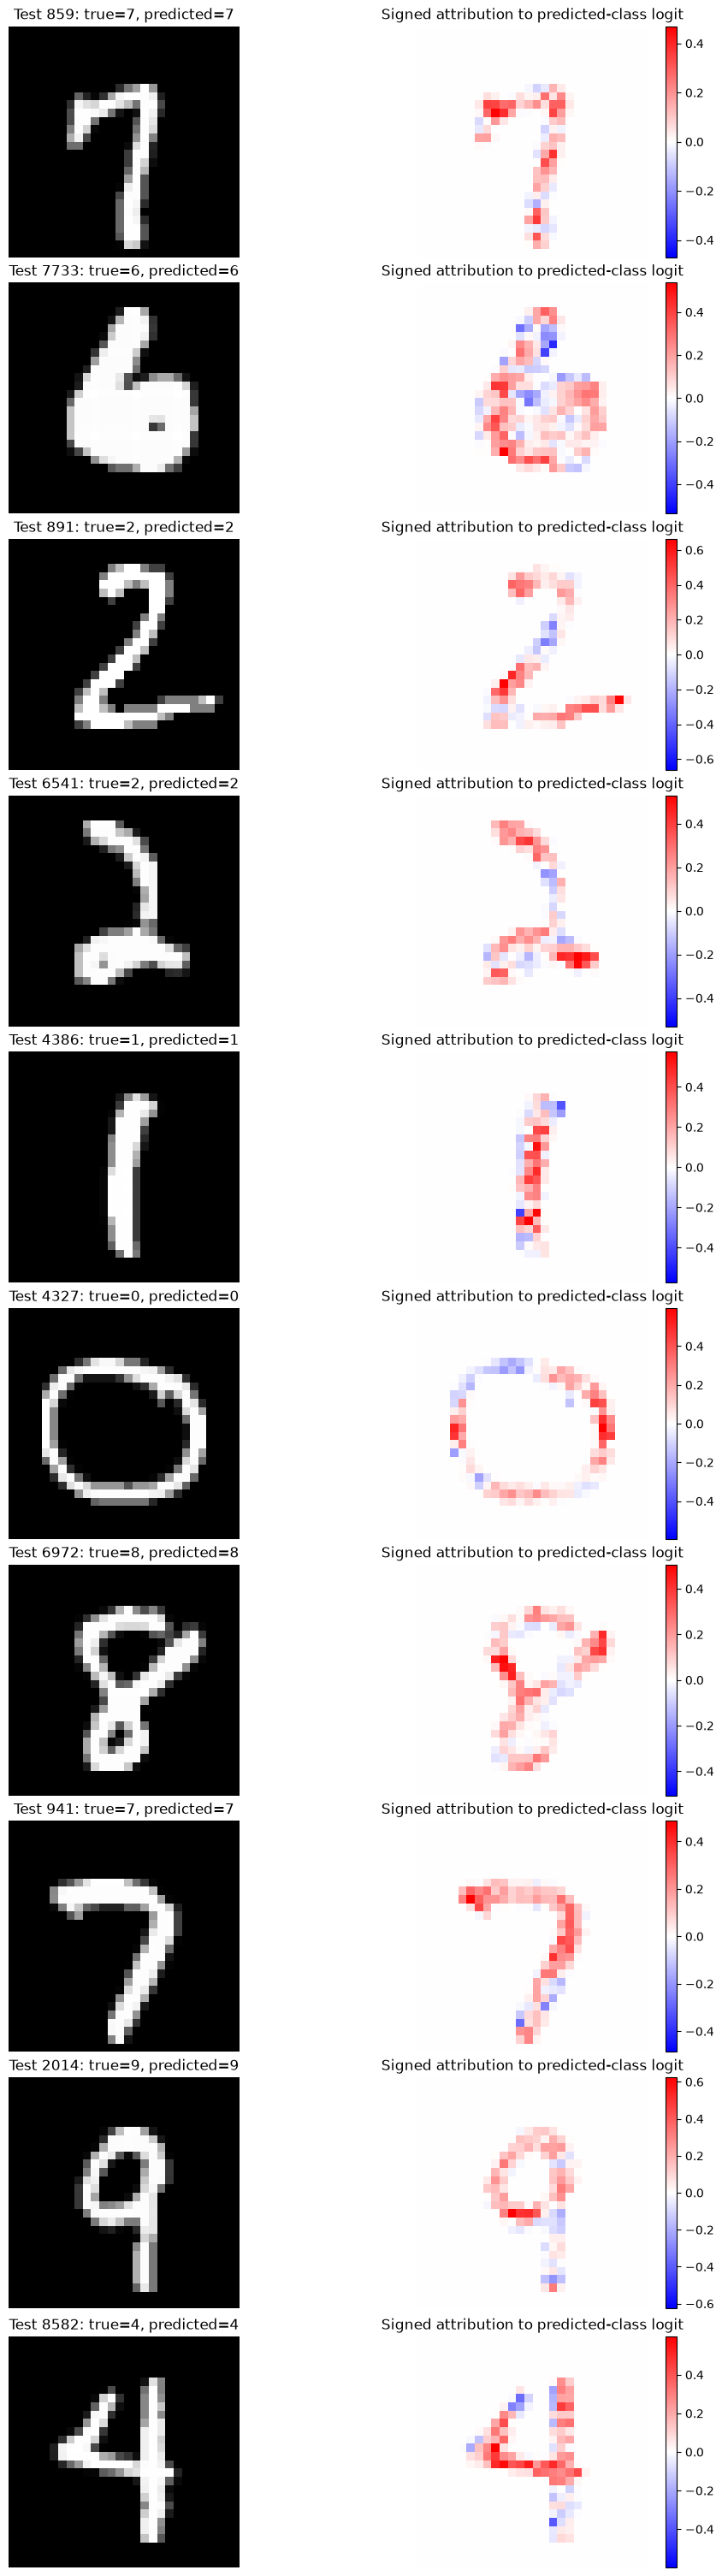

Red means positive contribution, blue means negative contribution, and white is near zero. These are signed contributions to the predicted-class logit, not magnitudes or probabilities. Each image has its own symmetric color scale, so use the colorbars when comparing strength across images. Black baseline pixels have zero input difference. The spatial summaries describe this model's evidence, not causal proof.

- **Test image 859 (true 7, predicted 7):** The middle center and upper center regions contain 59% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 1.039); red pixels support it (total positive attribution 10.392), relative to black.
- **Test image 7733 (true 6, predicted 6):** The middle center and lower center regions contain 50% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 6.548); red pixels support it (total positive attribution 19.839), relative to black.
- **Test image 891 (true 2, predicted 2):** The upper center and middle center regions contain 55% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 2.575); red pixels support it (total positive attribution 15.243), relative to black.
- **Test image 6541 (true 2, predicted 2):** The upper center and middle center regions contain 58% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 2.306); red pixels support it (total positive attribution 13.466), relative to black.
- **Test image 4386 (true 1, predicted 1):** The middle center and lower center regions contain 83% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 2.806); red pixels support it (total positive attribution 10.624), relative to black.
- **Test image 4327 (true 0, predicted 0):** The middle right and middle left regions contain 63% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 3.500); red pixels support it (total positive attribution 13.726), relative to black.
- **Test image 6972 (true 8, predicted 8):** The middle center and lower center regions contain 54% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 1.185); red pixels support it (total positive attribution 15.548), relative to black.
- **Test image 941 (true 7, predicted 7):** The middle center and upper left regions contain 57% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 1.374); red pixels support it (total positive attribution 13.810), relative to black.
- **Test image 2014 (true 9, predicted 9):** The middle center and upper center regions contain 83% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 2.199); red pixels support it (total positive attribution 11.786), relative to black.
- **Test image 8582 (true 4, predicted 4):** The middle center and middle left regions contain 77% of the positive attribution mass and provide the strongest regional support for the predicted digit. Blue pixels oppose that score (total negative magnitude 3.477); red pixels support it (total positive attribution 17.405), relative to black.

In [2]:
# Independent sampling RNG selects ten distinct test images with seed 42.
sample_indices = np.random.default_rng(42).choice(
    len(test_data), size=10, replace=False
)
images = torch.stack([test_data[int(index)][0] for index in sample_indices])
true_labels = [test_data[int(index)][1] for index in sample_indices]
model.eval()
with torch.no_grad():
    predictions = model(images).argmax(1)

integrated_gradients = IntegratedGradients(model)
attributions, deltas = integrated_gradients.attribute(
    images,
    baselines=torch.zeros_like(images),
    target=predictions,
    n_steps=100,
    internal_batch_size=20,
    return_convergence_delta=True,
)
print("Sample indices:", sample_indices.tolist())
print(f"Maximum absolute completeness residual: {deltas.abs().max().item():.6f}")

fig, axes = plt.subplots(10, 2, figsize=(9, 30), constrained_layout=True)
interpretations = []
for row, (image, attribution, true_label, prediction, index) in enumerate(
    zip(images, attributions, true_labels, predictions.tolist(), sample_indices)
):
    pixels = image[0].numpy()
    values = attribution[0].detach().numpy()
    limit = max(float(np.abs(values).max()), 1e-8)
    axes[row, 0].imshow(pixels, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Test {index}: true={true_label}, predicted={prediction}")
    heatmap = axes[row, 1].imshow(values, cmap="bwr", vmin=-limit, vmax=limit)
    axes[row, 1].set_title("Signed attribution to predicted-class logit")
    fig.colorbar(heatmap, ax=axes[row, 1], fraction=0.046)
    for ax in axes[row]:
        ax.axis("off")
    # Summarize the spatial distribution of positive evidence in a 3x3 grid.
    positive = np.maximum(values, 0)
    regions = []
    row_names = ["upper", "middle", "lower"]
    col_names = ["left", "center", "right"]
    for r, row_ids in enumerate(np.array_split(np.arange(28), 3)):
        for c, col_ids in enumerate(np.array_split(np.arange(28), 3)):
            regions.append(
                (
                    float(positive[np.ix_(row_ids, col_ids)].sum()),
                    f"{row_names[r]} {col_names[c]}",
                )
            )
    regions.sort(reverse=True)
    positive_total = float(positive.sum())
    share = (regions[0][0] + regions[1][0]) / max(positive_total, 1e-12)
    negative_total = float(np.maximum(-values, 0).sum())
    interpretations.append(
        f"- **Test image {index} (true {true_label}, predicted {prediction}):** "
        f"The {regions[0][1]} and {regions[1][1]} regions contain "
        f"{share:.0%} of the positive attribution mass and provide the strongest "
        f"regional support for the predicted digit. Blue pixels oppose that score "
        f"(total negative magnitude {negative_total:.3f}); red pixels support it "
        f"(total positive attribution {positive_total:.3f}), relative to black."
    )
plt.show()
display(
    Markdown(
        "Red means positive contribution, blue means negative contribution, "
        "and white is near zero. These are signed contributions to the "
        "predicted-class logit, not magnitudes or probabilities. Each image "
        "has its own symmetric color scale, so use the colorbars when "
        "comparing strength across images. Black baseline pixels have "
        "zero input difference. The spatial summaries describe this "
        "model's evidence, not causal proof.\n\n" + "\n".join(interpretations)
    )
)

In [3]:
model.eval()
export_path = project_root / "mnist_classifier.onnx"
torch.onnx.export(
    model,
    torch.zeros(1, 1, 28, 28),
    str(export_path),
    input_names=["images"],
    output_names=["logits"],
    opset_version=18,
    dynamo=False,
    dynamic_axes={"images": {0: "batch"}, "logits": {0: "batch"}},
)
onnx.checker.check_model(onnx.load(str(export_path)))
print(f"Exported and validated ONNX model: {export_path.name}")

Exported and validated ONNX model: mnist_classifier.onnx


/var/folders/cl/wdv8kj2x54j6z6wrz5rx4k540000gn/T/ipykernel_36581/3699311624.py:3: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
